In [1]:
from pathlib import Path
import pandas as pd

PROCESSED_DATA_DIR = Path("../data/processed")
FIGURES_DIR = Path("../figures")

games = pd.read_csv(PROCESSED_DATA_DIR / "games_clean.csv", low_memory=False)
print(games.shape)

(19824, 107)


In [2]:
# Stats already divided by game minutes
per_minute_feature_columns = [
    column + "_per_min" for column in [
        "kills", "deaths", "assists",
        "totalMinionsKilled", "neutralMinionsKilled", "goldEarned", "champExperience",
        "visionScore", "wardsPlaced", "wardsKilled", "detectorWardsPlaced",
        "totalDamageDealtToChampions", "damageDealtToBuildings",
        "challenges.dragonTakedowns", "challenges.baronTakedowns", "challenges.riftHeraldTakedowns",
        "challenges.voidMonsterKill", "challenges.turretTakedowns",
        "totalHealsOnTeammates", "totalDamageShieldedOnTeammates",
        "enemy_missing_pings", "info_pings",
    ]
]

# Stats that are already shares or yes/no, averaged as they are
per_game_rate_columns = per_minute_feature_columns + [
    "challenges.killParticipation", "challenges.teamDamagePercentage",
    "ended_with_oracle", "role_quest_completed", "win",
]

def most_common_role(roles):
    """The role a player played most often across their games."""
    role_counts = roles.dropna().value_counts()
    return role_counts.index[0] if len(role_counts) > 0 else None

def build_player_table(game_rows):
    """Turn one row per game into one row per player."""
    # Average of each stat over the player's games
    player_averages = game_rows.groupby("puuid")[per_game_rate_columns].mean()
    player_averages = player_averages.rename(columns={"win": "recent_win_rate"})

    # Values that are the same in every game of a player, plus edge-case counts
    player_details = game_rows.groupby("puuid").agg(
        main_role=("teamPosition", most_common_role),
        games_used=("match.matchId", "count"),
        server=("ladder.server", "first"),
        tier_index=("tier_index", "first"),
        summoner_level=("summonerLevel", "max"),
        season_games=("season_games", "first"),
        season_wr=("season_wr", "first"),
        veteran=("ladder.veteran", "first"),
        fresh_blood=("ladder.freshBlood", "first"),
        hot_streak=("ladder.hotStreak", "first"),
        autofilled_share=("autofilled", "mean"),
        remakes=("is_remake", "sum"),
        short_surrenders=("short_surrender", "sum"),
        afk_games=("player_afk", "sum"),
        teammate_afk_games=("teammate_afk", "sum"),
    )
    return player_averages.join(player_details).reset_index()

players = build_player_table(games)
print(players.shape)
print(players["tier_index"].value_counts().sort_index())
print(players["main_role"].value_counts())

(1361, 43)
tier_index
0    123
1    106
2    102
3     99
4    117
5    108
6    166
7    180
8    180
9    180
Name: count, dtype: int64
main_role
MIDDLE     320
BOTTOM     280
UTILITY    271
JUNGLE     254
TOP        236
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

# The columns the model learns from: averaged stats + account info
model_feature_columns = (
    [column for column in per_game_rate_columns if column != "win"]
    + ["recent_win_rate", "summoner_level", "season_games", "season_wr"]
)

# Hide 20% of players: random, but each tier keeps the same share on both sides
train_players, test_players = train_test_split(
    players,
    test_size=0.20,
    stratify=players["tier_index"],
    random_state=156,
)

print("Features:", len(model_feature_columns))
print("Train players:", len(train_players), "| Test players:", len(test_players))
print(pd.DataFrame({
    "train": train_players["tier_index"].value_counts().sort_index(),
    "test": test_players["tier_index"].value_counts().sort_index(),
}))

Features: 30
Train players: 1088 | Test players: 273
            train  test
tier_index             
0              98    25
1              85    21
2              82    20
3              79    20
4              93    24
5              86    22
6             133    33
7             144    36
8             144    36
9             144    36


In [4]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score

# Training data: X = the 30 feature columns, y = the tier (0 to 9)
X_train = train_players[model_feature_columns]
y_train = train_players["tier_index"]

# 5 folds, each with the same tier mix; fixed seed so every run uses the same folds
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=156)

results = []                  # one row of scores per run
validation_predictions = {}   # each run's predictions, for confusion matrices later

def within_one_tier_accuracy(true_tiers, predicted_tiers):
    """Share of players predicted within one tier of their real tier."""
    tier_distance = np.abs(np.asarray(true_tiers) - np.asarray(predicted_tiers))
    return np.mean(tier_distance <= 1)

def evaluate_run(run_name, model, X, y):
    """Predict every training player with 5-fold CV and record the scores."""
    # Each player is predicted by a model trained on the other 4 folds
    predicted_tiers = cross_val_predict(model, X, y, cv=cv_folds)

    run_scores = {
        "run": run_name,
        "accuracy": accuracy_score(y, predicted_tiers),
        "macro_f1": f1_score(y, predicted_tiers, average="macro", zero_division=0),
        "within_one_tier": within_one_tier_accuracy(y, predicted_tiers),
        "mean_tier_error": np.mean(np.abs(np.asarray(y) - predicted_tiers)),
    }

    # Rerunning a run replaces its old row instead of adding a duplicate
    results[:] = [row for row in results if row["run"] != run_name]
    results.append(run_scores)
    validation_predictions[run_name] = predicted_tiers
    return pd.Series(run_scores)

In [5]:
from sklearn.dummy import DummyClassifier

# Always predicts the tier that's most common in the training folds
baseline_model = DummyClassifier(strategy="most_frequent")
evaluate_run("1. Baseline (most common tier)", baseline_model, X_train, y_train)

run                1. Baseline (most common tier)
accuracy                                 0.132353
macro_f1                                 0.023377
within_one_tier                          0.386949
mean_tier_error                          2.700368
dtype: object

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Logistic regression can't handle blanks, so check first
print("Blank values in X_train:", X_train.isna().sum().sum())

# Step 1: put every feature on the same scale. Step 2: logistic regression.
logistic_raw_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)
evaluate_run("2. Logistic regression, raw stats", logistic_raw_model, X_train, y_train)

Blank values in X_train: 0


run                2. Logistic regression, raw stats
accuracy                                    0.348346
macro_f1                                    0.314796
within_one_tier                              0.73989
mean_tier_error                             1.086397
dtype: object

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin

class WithinRoleScaler(BaseEstimator, TransformerMixin):
    """Turn each stat into a z-score against players of the same main role.
    Role means and stds are learned from the training folds only."""

    def __init__(self, feature_columns, role_column="main_role"):
        self.feature_columns = feature_columns
        self.role_column = role_column

    def fit(self, X, y=None):
        # Average and spread of every stat, separately for each role
        stats_by_role = X.groupby(self.role_column)[self.feature_columns]
        self.role_means_ = stats_by_role.mean()
        self.role_stds_ = stats_by_role.std().replace(0, 1)  # avoid dividing by 0
        return self

    def transform(self, X):
        # Look up each player's role average and spread, then compare
        player_roles = X[self.role_column]
        means_for_each_player = self.role_means_.loc[player_roles].to_numpy()
        stds_for_each_player = self.role_stds_.loc[player_roles].to_numpy()
        return (X[self.feature_columns].to_numpy() - means_for_each_player) / stds_for_each_player

# Same players, plus their main role so the scaler knows who to compare them with
X_train_with_role = train_players[model_feature_columns + ["main_role"]]

logistic_within_role_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    LogisticRegression(max_iter=2000),
)
evaluate_run("3. Logistic regression, within role", logistic_within_role_model,
             X_train_with_role, y_train)

run                3. Logistic regression, within role
accuracy                                      0.330882
macro_f1                                       0.29793
within_one_tier                               0.722426
mean_tier_error                               1.140625
dtype: object

In [9]:
from sklearn.ensemble import RandomForestClassifier

random_forest_within_role_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RandomForestClassifier(n_estimators=500, random_state=156, n_jobs=-1),
)
evaluate_run("4. Random forest, within role", random_forest_within_role_model,
             X_train_with_role, y_train)

run                4. Random forest, within role
accuracy                                0.357537
macro_f1                                0.316745
within_one_tier                         0.725184
mean_tier_error                         1.095588
dtype: object

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

gradient_boosting_within_role_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    HistGradientBoostingClassifier(random_state=156),
)
evaluate_run("5. Gradient boosting, within role", gradient_boosting_within_role_model,
             X_train_with_role, y_train)

run                5. Gradient boosting, within role
accuracy                                    0.338235
macro_f1                                    0.306594
within_one_tier                             0.732537
mean_tier_error                             1.107537
dtype: object

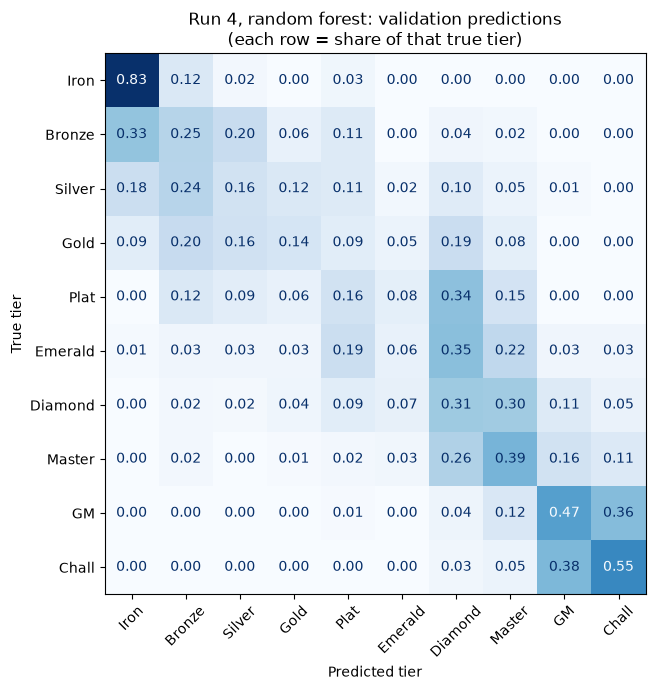

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

tier_names = ["Iron", "Bronze", "Silver", "Gold", "Plat", "Emerald",
              "Diamond", "Master", "GM", "Chall"]

figure, axis = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    validation_predictions["4. Random forest, within role"],
    display_labels=tier_names,
    normalize="true",        # each row shows shares of that true tier
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_xlabel("Predicted tier")
axis.set_ylabel("True tier")
axis.set_title("Run 4, random forest: validation predictions\n(each row = share of that true tier)")
plt.setp(axis.get_xticklabels(), rotation=45)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "confusion_matrix_run4_validation.png", dpi=150)
plt.show()

In [12]:
random_forest_balanced_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RandomForestClassifier(n_estimators=500, class_weight="balanced",
                           random_state=156, n_jobs=-1),
)
evaluate_run("4b. Random forest, within role, balanced", random_forest_balanced_model,
             X_train_with_role, y_train)

run                4b. Random forest, within role, balanced
accuracy                                           0.346507
macro_f1                                           0.320278
within_one_tier                                    0.721507
mean_tier_error                                    1.100184
dtype: object

In [13]:
from sklearn.base import RegressorMixin, clone
from sklearn.ensemble import RandomForestRegressor

class RoundedTierRegressor(BaseEstimator, RegressorMixin):
    """Predict the tier as a number, then round to the nearest tier (0 to 9)."""

    def __init__(self, regressor):
        self.regressor = regressor

    def fit(self, X, y):
        self.regressor_ = clone(self.regressor).fit(X, y)
        return self

    def predict(self, X):
        predicted_numbers = self.regressor_.predict(X)
        # Round to the nearest whole tier and keep it between Iron (0) and Challenger (9)
        return np.clip(np.rint(predicted_numbers), 0, 9).astype(int)

tier_as_number_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
evaluate_run("6. Random forest, tier as a number", tier_as_number_model,
             X_train_with_role, y_train)

run                6. Random forest, tier as a number
accuracy                                     0.317096
macro_f1                                      0.30741
within_one_tier                              0.783088
mean_tier_error                              0.973346
dtype: object

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

# Per-game versions of the player features (one game's values instead of averages)
game_feature_columns = per_minute_feature_columns + [
    "challenges.killParticipation", "challenges.teamDamagePercentage",
    "ended_with_oracle", "role_quest_completed", "win",
    "summonerLevel", "season_games", "season_wr",
]

# Games of the training players only; the 2 games with no role are left out
train_games = games[games["puuid"].isin(train_players["puuid"])
                    & games["teamPosition"].notna()].copy()
train_games["challenges.teamDamagePercentage"] = (
    train_games["challenges.teamDamagePercentage"].fillna(0))   # blank only in remakes
train_games["win"] = train_games["win"].astype(int)
train_games["main_role"] = train_games["teamPosition"]          # compare each game with games in the same role

X_train_games = train_games[game_feature_columns + ["main_role"]]
y_train_games = train_games["tier_index"]

# Folds split by player: all of a player's games stay in the same fold
player_grouped_folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=156)

# 200 trees instead of 500: about 15,800 rows instead of 1,088, so 500 would take several minutes
single_game_model = make_pipeline(
    WithinRoleScaler(feature_columns=game_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=200, random_state=156, n_jobs=-1)),
)
predicted_game_tiers = cross_val_predict(single_game_model, X_train_games, y_train_games,
                                         cv=player_grouped_folds, groups=train_games["puuid"])

run_name = "7. Forest, tier as number, single games"
run_scores = {
    "run": run_name,
    "accuracy": accuracy_score(y_train_games, predicted_game_tiers),
    "macro_f1": f1_score(y_train_games, predicted_game_tiers, average="macro", zero_division=0),
    "within_one_tier": within_one_tier_accuracy(y_train_games, predicted_game_tiers),
    "mean_tier_error": np.mean(np.abs(y_train_games.to_numpy() - predicted_game_tiers)),
}
results[:] = [row for row in results if row["run"] != run_name]
results.append(run_scores)
validation_predictions[run_name] = predicted_game_tiers

print("Training games:", len(train_games))
pd.Series(run_scores)

Training games: 15819


run                7. Forest, tier as number, single games
accuracy                                          0.333207
macro_f1                                          0.324962
within_one_tier                                   0.771541
mean_tier_error                                   0.995765
dtype: object

In [15]:
account_feature_columns = ["summoner_level", "season_games", "season_wr"]
gameplay_feature_columns = [column for column in model_feature_columns
                            if column not in account_feature_columns]

gameplay_only_model = make_pipeline(
    WithinRoleScaler(feature_columns=gameplay_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
evaluate_run("8. Forest, tier as number, gameplay only", gameplay_only_model,
             train_players[gameplay_feature_columns + ["main_role"]], y_train)

run                8. Forest, tier as number, gameplay only
accuracy                                           0.206801
macro_f1                                           0.194906
within_one_tier                                    0.580882
mean_tier_error                                    1.466912
dtype: object

In [16]:
account_only_model = make_pipeline(
    WithinRoleScaler(feature_columns=account_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
evaluate_run("8b. Forest, tier as number, account only", account_only_model,
             train_players[account_feature_columns + ["main_role"]], y_train)

run                8b. Forest, tier as number, account only
accuracy                                            0.29136
macro_f1                                           0.285888
within_one_tier                                    0.735294
mean_tier_error                                    1.100184
dtype: object

In [17]:
ping_feature_columns = ["enemy_missing_pings_per_min", "info_pings_per_min"]
no_ping_feature_columns = [column for column in model_feature_columns
                           if column not in ping_feature_columns]

no_pings_model = make_pipeline(
    WithinRoleScaler(feature_columns=no_ping_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
evaluate_run("9. Forest, tier as number, no pings", no_pings_model,
             train_players[no_ping_feature_columns + ["main_role"]], y_train)

run                9. Forest, tier as number, no pings
accuracy                                      0.307904
macro_f1                                      0.299853
within_one_tier                               0.779412
mean_tier_error                               0.988971
dtype: object

In [18]:
# Games where the result says little about the player's skill
edge_case_flags = ["is_remake", "short_surrender", "player_afk",
                   "teammate_afk", "is_ignb", "griefer"]
clean_game_mask = ~games[edge_case_flags].any(axis=1)
print("Games removed:", (~clean_game_mask).sum(), "of", len(games))

# Rebuild every player's averages from the remaining games only
players_without_edge_cases = build_player_table(games[clean_game_mask])

# Same training players, in the same order as before, so the 5 folds match Run 6
train_players_without_edge_cases = (
    players_without_edge_cases.set_index("puuid")
    .reindex(train_players["puuid"])
    .reset_index()
    .dropna(subset=["tier_index"])      # a player whose games were all removed
)
print("Training players:", len(train_players_without_edge_cases))

no_edge_cases_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
evaluate_run("10. Forest, tier as number, edge cases removed", no_edge_cases_model,
             train_players_without_edge_cases[model_feature_columns + ["main_role"]],
             train_players_without_edge_cases["tier_index"].astype(int))

Games removed: 1053 of 19824
Training players: 1088


run                10. Forest, tier as number, edge cases removed
accuracy                                                 0.326287
macro_f1                                                 0.314946
within_one_tier                                          0.780331
mean_tier_error                                          0.972426
dtype: object

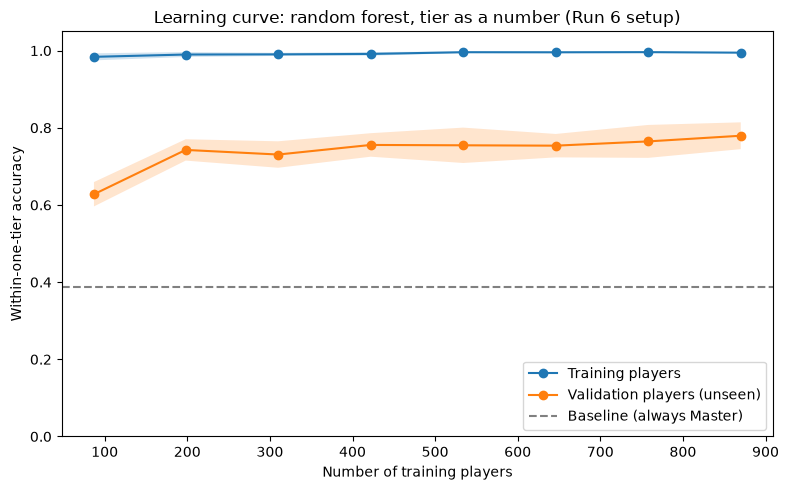

,training_players,training_score,validation_score
0,87,0.984,0.628
1,198,0.990,0.743
2,310,0.990,0.731
3,422,0.991,0.756
4,534,0.996,0.755
5,646,0.996,0.754
6,758,0.996,0.765
7,870,0.995,0.779


In [19]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import make_scorer

# The final model: Run 6's setup
best_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)

# Score with your own metric
within_one_tier_scorer = make_scorer(within_one_tier_accuracy)

# Train on 10%, 23%, ... 100% of each training fold; score on the fold left out
training_sizes, training_scores, validation_scores = learning_curve(
    best_model, X_train_with_role, y_train,
    cv=cv_folds,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring=within_one_tier_scorer,
    shuffle=True, random_state=156,
)

figure, axis = plt.subplots(figsize=(8, 5))
for scores, label in [(training_scores, "Training players"),
                      (validation_scores, "Validation players (unseen)")]:
    mean_score = scores.mean(axis=1)
    spread = scores.std(axis=1)               # how much the 5 folds disagree
    axis.plot(training_sizes, mean_score, marker="o", label=label)
    axis.fill_between(training_sizes, mean_score - spread, mean_score + spread, alpha=0.2)

axis.axhline(0.387, color="gray", linestyle="--", label="Baseline (always Master)")
axis.set_xlabel("Number of training players")
axis.set_ylabel("Within-one-tier accuracy")
axis.set_ylim(0, 1.05)
axis.set_title("Learning curve: random forest, tier as a number (Run 6 setup)")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "learning_curve.png", dpi=150)
plt.show()

pd.DataFrame({
    "training_players": training_sizes,
    "training_score": training_scores.mean(axis=1).round(3),
    "validation_score": validation_scores.mean(axis=1).round(3),
})

                                           run  accuracy  macro_f1  within_one_tier  mean_tier_error
                1. Baseline (most common tier)     0.132     0.023            0.387            2.700
             2. Logistic regression, raw stats     0.348     0.315            0.740            1.086
           3. Logistic regression, within role     0.331     0.298            0.722            1.141
                 4. Random forest, within role     0.358     0.317            0.725            1.096
             5. Gradient boosting, within role     0.338     0.307            0.733            1.108
      4b. Random forest, within role, balanced     0.347     0.320            0.722            1.100
            6. Random forest, tier as a number     0.317     0.307            0.783            0.973
       7. Forest, tier as number, single games     0.333     0.325            0.772            0.996
      8. Forest, tier as number, gameplay only     0.207     0.195            0.581        

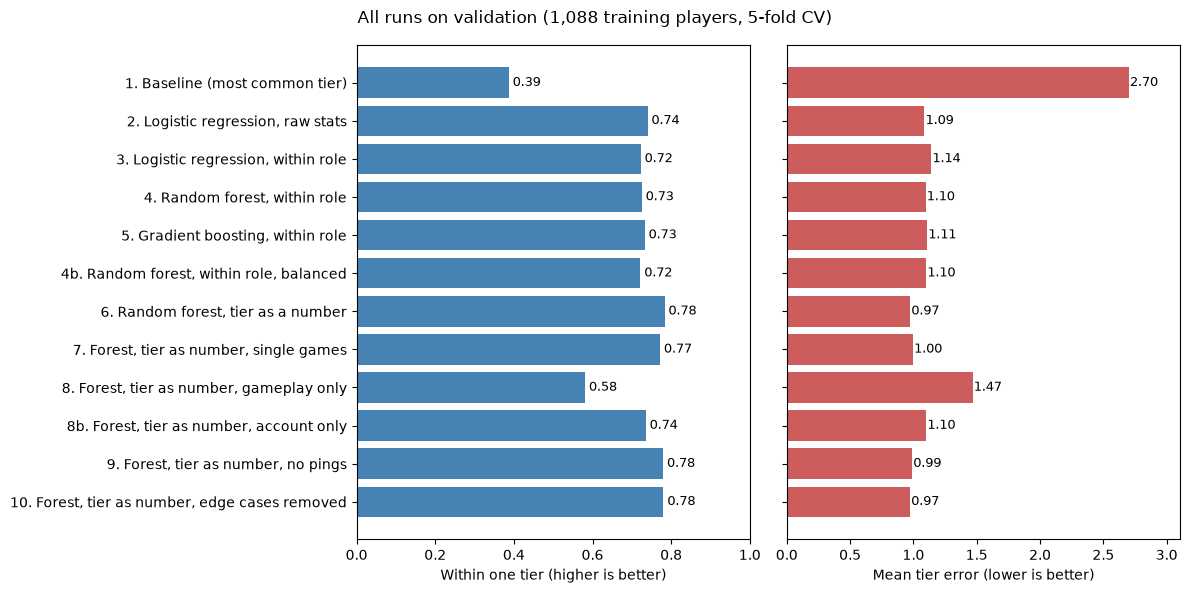

In [23]:
results_table = pd.DataFrame(results)
run_name_column = results_table.columns[0]
print(results_table.round(3).to_string(index=False))

fig, (within_one_axis, error_axis) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

within_one_axis.barh(results_table[run_name_column], results_table["within_one_tier"], color="steelblue")
within_one_axis.set_xlabel("Within one tier (higher is better)")
within_one_axis.set_xlim(0, 1)

error_axis.barh(results_table[run_name_column], results_table["mean_tier_error"], color="indianred")
error_axis.set_xlabel("Mean tier error (lower is better)")
error_axis.set_xlim(0, results_table["mean_tier_error"].max() * 1.15)

for axis, score_column in [(within_one_axis, "within_one_tier"), (error_axis, "mean_tier_error")]:
    for bar_position, score_value in enumerate(results_table[score_column]):
        axis.text(score_value + 0.01, bar_position, f"{score_value:.2f}", va="center", fontsize=9)

within_one_axis.invert_yaxis()
fig.suptitle("All runs on validation (1,088 training players, 5-fold CV)")
fig.tight_layout()
fig.savefig("../figures/run_comparison.png", dpi=150)
plt.show()

Final test, 273 hidden players:
accuracy           0.348
macro_f1           0.336
within_one_tier    0.828
mean_tier_error    0.886
dtype: float64


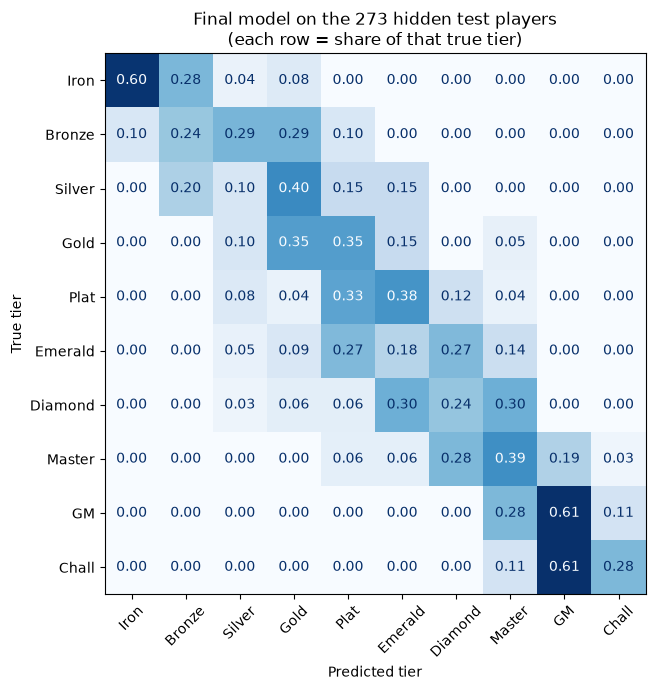

In [20]:
# The hidden players, untouched since Cell 3
X_test_with_role = test_players[model_feature_columns + ["main_role"]]
y_test = test_players["tier_index"]

# Final model = Run 6 setup, trained on ALL 1,088 training players this time
final_model = make_pipeline(
    WithinRoleScaler(feature_columns=model_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
final_model.fit(X_train_with_role, y_train)
test_predicted_tiers = final_model.predict(X_test_with_role)

final_test_scores = pd.Series({
    "accuracy": accuracy_score(y_test, test_predicted_tiers),
    "macro_f1": f1_score(y_test, test_predicted_tiers, average="macro", zero_division=0),
    "within_one_tier": within_one_tier_accuracy(y_test, test_predicted_tiers),
    "mean_tier_error": np.mean(np.abs(y_test.to_numpy() - test_predicted_tiers)),
})
print("Final test, 273 hidden players:")
print(final_test_scores.round(3))

# Figure 6: test confusion matrix
figure, axis = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predicted_tiers,
    labels=range(10),
    display_labels=tier_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_xlabel("Predicted tier")
axis.set_ylabel("True tier")
axis.set_title("Final model on the 273 hidden test players\n(each row = share of that true tier)")
plt.setp(axis.get_xticklabels(), rotation=45)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "confusion_matrix_final_test.png", dpi=150)
plt.show()

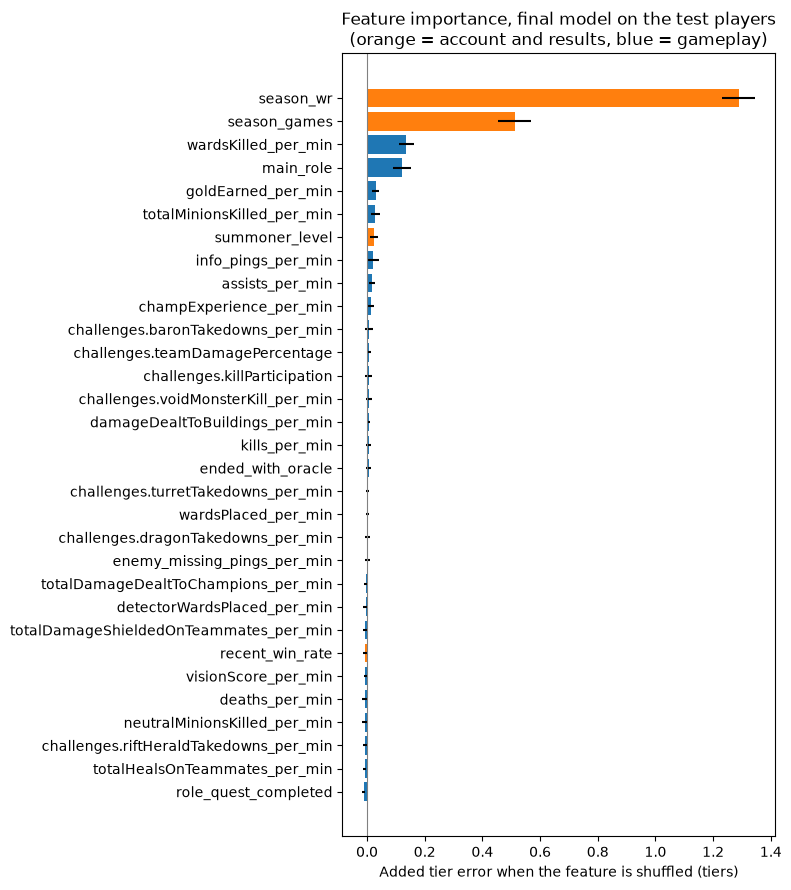

,feature,added_error,spread
29,season_wr,1.288,0.058
28,season_games,0.512,0.058
9,wardsKilled_per_min,0.136,0.026
30,main_role,0.121,0.032
5,goldEarned_per_min,0.030,0.013
3,totalMinionsKilled_per_min,0.029,0.015
27,summoner_level,0.025,0.014
21,info_pings_per_min,0.022,0.018
2,assists_per_min,0.017,0.010
6,champExperience_per_min,0.013,0.010


In [21]:
from sklearn.inspection import permutation_importance

def mean_tier_error(true_tiers, predicted_tiers):
    return np.mean(np.abs(np.asarray(true_tiers) - np.asarray(predicted_tiers)))

# Lower error is better, so the scorer flips the sign
mean_tier_error_scorer = make_scorer(mean_tier_error, greater_is_better=False)

# Shuffle one column at a time, 20 times each, and measure how much worse the model gets
importance_result = permutation_importance(
    final_model, X_test_with_role, y_test,
    scoring=mean_tier_error_scorer,
    n_repeats=20, random_state=156,
)

feature_importance = pd.DataFrame({
    "feature": X_test_with_role.columns,
    "added_error": importance_result.importances_mean,
    "spread": importance_result.importances_std,
}).sort_values("added_error", ascending=True)

# Orange = account and results columns, blue = gameplay
account_columns = account_feature_columns + ["recent_win_rate"]
bar_colors = ["tab:orange" if feature in account_columns else "tab:blue"
              for feature in feature_importance["feature"]]

figure, axis = plt.subplots(figsize=(8, 9))
axis.barh(feature_importance["feature"], feature_importance["added_error"],
          xerr=feature_importance["spread"], color=bar_colors)
axis.axvline(0, color="gray", linewidth=0.8)
axis.set_xlabel("Added tier error when the feature is shuffled (tiers)")
axis.set_title("Feature importance, final model on the test players\n"
               "(orange = account and results, blue = gameplay)")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "feature_importance.png", dpi=150)
plt.show()

feature_importance.sort_values("added_error", ascending=False).head(10).round(3)

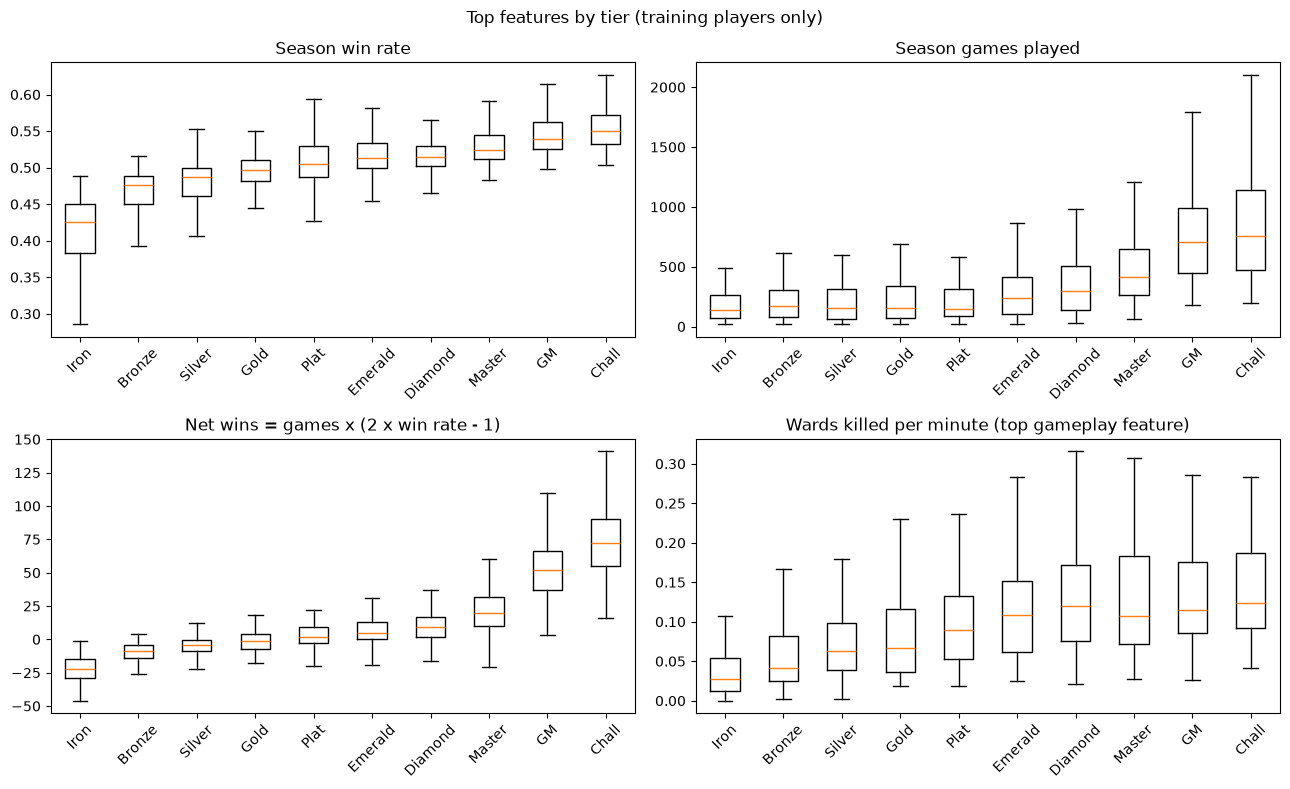

         season_wr  season_games  net_wins  wardsKilled_per_min
Iron         0.425         139.5     -22.5                0.027
Bronze       0.476         174.0      -9.0                0.042
Silver       0.487         158.0      -4.0                0.063
Gold         0.497         156.0      -1.0                0.067
Plat         0.505         149.0       2.0                0.089
Emerald      0.513         237.5       5.0                0.109
Diamond      0.514         301.0       9.0                0.120
Master       0.524         417.5      20.0                0.108
GM           0.540         710.5      52.0                0.115
Chall        0.550         759.0      72.0                0.124


In [24]:
tier_plot_players = train_players.copy()
tier_plot_players["net_wins"] = tier_plot_players["season_games"] * (2 * tier_plot_players["season_wr"] - 1)

columns_to_plot = {
    "season_wr": "Season win rate",
    "season_games": "Season games played",
    "net_wins": "Net wins = games x (2 x win rate - 1)",
    "wardsKilled_per_min": "Wards killed per minute (top gameplay feature)",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, (column_name, plot_title) in zip(axes.ravel(), columns_to_plot.items()):
    values_by_tier = [tier_plot_players.loc[tier_plot_players["tier_index"] == tier, column_name] for tier in range(10)]
    axis.boxplot(values_by_tier, showfliers=False)
    axis.set_xticks(range(1, 11), tier_names, rotation=45)
    axis.set_title(plot_title)

fig.suptitle("Top features by tier (training players only)")
fig.tight_layout()
fig.savefig("../figures/features_by_tier.png", dpi=150)
plt.show()

median_by_tier = tier_plot_players.groupby("tier_index")[list(columns_to_plot)].median().set_axis(tier_names)
print(median_by_tier.round(3))

In [25]:
test_error_table = test_players[["tier_index", "fresh_blood", "hot_streak", "summoner_level"]].copy()
test_error_table["predicted_tier"] = final_model.predict(X_test_with_role)
test_error_table["signed_error"] = test_error_table["predicted_tier"] - test_error_table["tier_index"]
test_error_table["tier_error"] = test_error_table["signed_error"].abs()

low_level_cutoff = train_players["summoner_level"].quantile(0.25)
test_error_table["low_level_account"] = test_error_table["summoner_level"] < low_level_cutoff
print(f"Low-level cutoff (bottom 25% of training players): level {low_level_cutoff:.0f}\n")

for group_column in ["fresh_blood", "hot_streak", "low_level_account"]:
    group_summary = test_error_table.groupby(group_column).agg(
        players=("tier_error", "size"),
        mean_tier_error=("tier_error", "mean"),
        mean_signed_error=("signed_error", "mean"),
        within_one_tier=("tier_error", lambda errors: (errors <= 1).mean()),
    )
    print(group_column)
    print(group_summary.round(3), "\n")

Low-level cutoff (bottom 25% of training players): level 185

fresh_blood
             players  mean_tier_error  mean_signed_error  within_one_tier
fresh_blood                                                              
False            238            0.887              0.080            0.828
True              35            0.886              0.086            0.829 

hot_streak
            players  mean_tier_error  mean_signed_error  within_one_tier
hot_streak                                                              
False           232            0.858              0.142            0.836
True             41            1.049             -0.268            0.780 

low_level_account
                   players  mean_tier_error  mean_signed_error  \
low_level_account                                                
False                  202            0.866             -0.035   
True                    71            0.944              0.408   

                   within_one_tier  
low

In [22]:
gameplay_final_model = make_pipeline(
    WithinRoleScaler(feature_columns=gameplay_feature_columns),
    RoundedTierRegressor(RandomForestRegressor(n_estimators=500, random_state=156, n_jobs=-1)),
)
gameplay_final_model.fit(train_players[gameplay_feature_columns + ["main_role"]], y_train)
gameplay_test_predictions = gameplay_final_model.predict(
    test_players[gameplay_feature_columns + ["main_role"]])

gameplay_test_scores = pd.Series({
    "accuracy": accuracy_score(y_test, gameplay_test_predictions),
    "macro_f1": f1_score(y_test, gameplay_test_predictions, average="macro", zero_division=0),
    "within_one_tier": within_one_tier_accuracy(y_test, gameplay_test_predictions),
    "mean_tier_error": mean_tier_error(y_test, gameplay_test_predictions),
})
pd.DataFrame({"all features (Run 6)": final_test_scores,
              "gameplay only (Run 8)": gameplay_test_scores}).round(3)

,all features (Run 6),gameplay only (Run 8)
accuracy,0.348,0.187
macro_f1,0.336,0.172
within_one_tier,0.828,0.630
mean_tier_error,0.886,1.440
